In [1]:
%load_ext autoreload
%autoreload 2

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("OpenCV:", cv2.__version__)

from rppg_step1_3 import (inspect_video, load_ground_truth,
                          extract_rgb_signals, VIDEO_PATH, GT_PATH)

print("\n=== STEP 1: video ===")
info = inspect_video(VIDEO_PATH)
for k, v in info.items():
    print(k, ":", v)

print("\n=== STEP 2: ground truth ===")
gt = load_ground_truth(GT_PATH)

OpenCV: 4.14.0

=== STEP 1: video ===
fps : 29.264106
width : 640
height : 480
frame_count_reported : 1547
duration_sec_reported : 52.863395177696525

=== STEP 2: ground truth ===
[GT] raw shape: (3, 1547)
[GT] samples: 1547
[GT] time range: 0.00s -> 52.69s
[GT] average sampling frequency: 29.34 Hz
[GT] HR min/mean/max: 97.0 / 106.7 / 113.0 BPM


[RGB] frames processed: 300
[RGB] frames with no fresh face detection: 0 (last known box was reused for these)
(300, 15)
face detected fraction: 1.0


,frame,time_s,face_detected,forehead_R,forehead_G,forehead_B,left_cheek_R,left_cheek_G,left_cheek_B,right_cheek_R,right_cheek_G,right_cheek_B,combined_R,combined_G,combined_B
0,0,0.000000,1,209.597241,164.882759,162.333793,190.012311,145.682765,144.655303,190.839015,145.621212,144.160038,196.816189,152.062245,150.383045
1,1,0.034172,1,209.576552,164.677241,162.277241,190.061553,145.720644,144.708333,190.671402,145.452652,144.282197,196.769835,151.950179,150.422591
2,2,0.068343,1,209.491724,164.606207,162.152414,190.107955,145.695076,144.793561,190.478220,145.413826,143.981061,196.692633,151.905036,150.309012
3,3,0.102515,1,209.244068,164.232542,161.629831,188.314617,144.388592,143.485740,189.853994,145.108356,143.408632,195.804226,151.243163,149.508067
4,4,0.136686,1,209.126780,164.028475,161.750508,188.826287,144.698529,143.745404,190.427083,145.361742,143.994318,196.126717,151.362915,149.830077


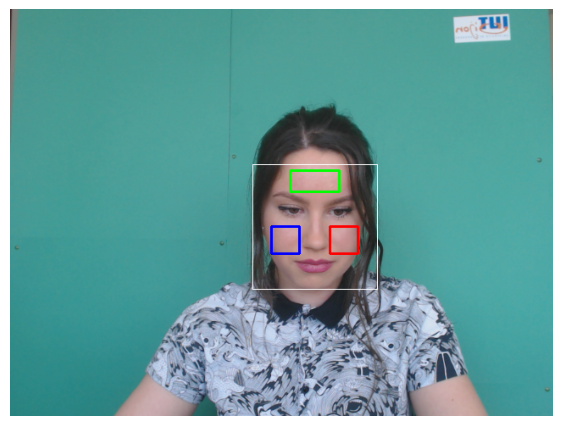

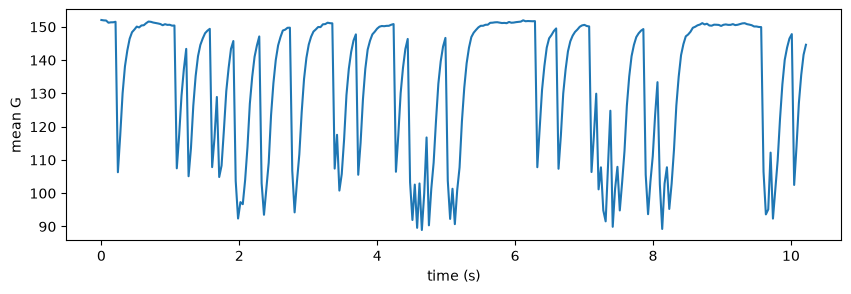

In [2]:
df = extract_rgb_signals(VIDEO_PATH, info["fps"], max_frames=300)
print(df.shape)
print("face detected fraction:", df["face_detected"].mean())
display(df.head())

img = cv2.imread("outputs/subject1/debug_roi_frame0.png")
plt.figure(figsize=(7, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(df["time_s"], df["combined_G"])
plt.xlabel("time (s)")
plt.ylabel("mean G")
plt.show()